# 08 · Feature normalization

Fit per-band statistics on original training frames and freeze them for every partition.

Run notebooks **01 → 09** in order. This notebook contains its implementation directly; it does not import project code from `src/`.

In [1]:
from pathlib import Path
import json
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from IPython import get_ipython
get_ipython().run_line_magic("matplotlib", "inline")

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "configs/preprocessing.json").exists())
cfg = json.loads((root / "configs/preprocessing.json").read_text())
out = root / "data/processed" / cfg["run_name"]
reports = root / "reports/preprocessing" / cfg["run_name"]
out.mkdir(parents=True, exist_ok=True)
reports.mkdir(parents=True, exist_ok=True)

In [2]:
def load_manifest(name):
    path = out / name
    if not path.exists():
        raise FileNotFoundError(f"Run the preceding notebook first: {path}")
    return [json.loads(line) for line in path.read_text().splitlines()]

def save_manifest(name, rows):
    path = out / name
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w") as stream:
        for row in rows:
            stream.write(json.dumps(row, allow_nan=False) + "\n")

def save_json(path, value):
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(value, indent=2, allow_nan=False) + "\n")

## Fit without leakage

Generated variants, validation, and test clips do not contribute to the mean or standard deviation.

### Math for the next code block — training-only moments

Let $\mathcal{T}$ contain every frame from original, non-augmented training clips. For Mel band $r$ and $Q=|\mathcal{T}|$ frames:

$$\mu_r=\frac1Q\sum_{t\in\mathcal{T}}F[t,r],$$

$$\sigma_r=\max\!\left(\sqrt{\frac1Q\sum_{t\in\mathcal{T}}F[t,r]^2-\mu_r^2},\;10^{-5}\right).$$

Validation, test, and augmented frames do not enter these estimates. The code accumulates sums in float64 to reduce numerical error.

In [3]:
rows=load_manifest("07_features.jsonl")
total=np.zeros(cfg["mel_bands"],dtype=np.float64)
squares=total.copy()
frame_count=0
fit_ids=[]
for record in rows:
    if record["split"]!="train" or record["is_augmented"]: 
        continue
    values=np.load(root/record["feature_path"]).astype(np.float64)
    total+=values.sum(axis=0)
    squares+=(values*values).sum(axis=0)
    frame_count+=len(values)
    fit_ids.append(record["id"])
if not frame_count: 
    raise ValueError("No original training frames")
mean=total/frame_count
std=np.sqrt(np.maximum(squares/frame_count-mean**2,0))
std=np.maximum(std,cfg["normalization_std_floor"])

In [4]:
directory=out/"08_normalized"
directory.mkdir(parents=True,exist_ok=True)
np.savez(directory/"training_statistics.npz",mean=mean,std=std)
metadata={
    "fit_scope":"original_training_frames_only",
    "fit_clips":len(fit_ids),
    "fit_frames":frame_count,
    "fit_ids_sha256":hashlib.sha256("\n".join(sorted(fit_ids)).encode()).hexdigest(),
    "fit_ids":sorted(fit_ids)
}
save_json(directory/"statistics_provenance.json",metadata)

### Math for the next code block — frozen standardization

Every feature matrix uses the same training statistics:

$$Z[t,r]=\frac{F[t,r]-\mu_r}{\sigma_r}.$$

The operation is per Mel band and preserves the matrix shape $T\times40$.

In [5]:
normalized=[]
for record in rows:
    path=directory/record["split"]/f"{record['id']}.npy"
    path.parent.mkdir(parents=True,exist_ok=True)
    values=np.load(root/record["feature_path"])
    np.save(path,((values-mean)/std).astype(np.float32))
    normalized.append({**record,"normalized_path":str(path.relative_to(root))})
save_manifest("08_normalized.jsonl",normalized)
display({key:metadata[key] for key in ("fit_scope","fit_clips","fit_frames","fit_ids_sha256")})

{'fit_scope': 'original_training_frames_only',
 'fit_clips': 6357,
 'fit_frames': 612796,
 'fit_ids_sha256': '31e8bfb46af30f6be0f015a9502c42de0883143928507a503abd8b8138ed609c'}

## Check frozen statistics

Training originals should aggregate to mean zero and standard deviation one. Evaluation partitions can differ.

In [6]:
INK, MUTED, BLUE, TEAL, AMBER, RED = "#152b42", "#586c7d", "#3265bb", "#087f8c", "#ba6b10", "#bf4545"
plt.rcParams.update({"figure.facecolor":"#f4f7fb", "axes.facecolor":"white",
                     "axes.edgecolor":"#c8d5e2", "axes.labelcolor":INK,
                     "xtick.color":MUTED, "ytick.color":MUTED, "font.size":11})

def finish_figure(fig, name):
    directory = reports / "figures"
    directory.mkdir(parents=True, exist_ok=True)
    fig.savefig(directory / f"{name}.png", dpi=170, bbox_inches="tight")
    fig.savefig(directory / f"{name}.svg", bbox_inches="tight")
    plt.show()

### Math for the next code block — diagnostic moments

For each split, the plot recomputes

$$\bar z_r=\frac1Q\sum_t Z[t,r],\qquad
s_r=\sqrt{\frac1Q\sum_tZ[t,r]^2-\bar z_r^2}.$$

Original training frames should give $\bar z_r\approx0$ and $s_r\approx1$. Validation and test can differ because their statistics are not refitted.

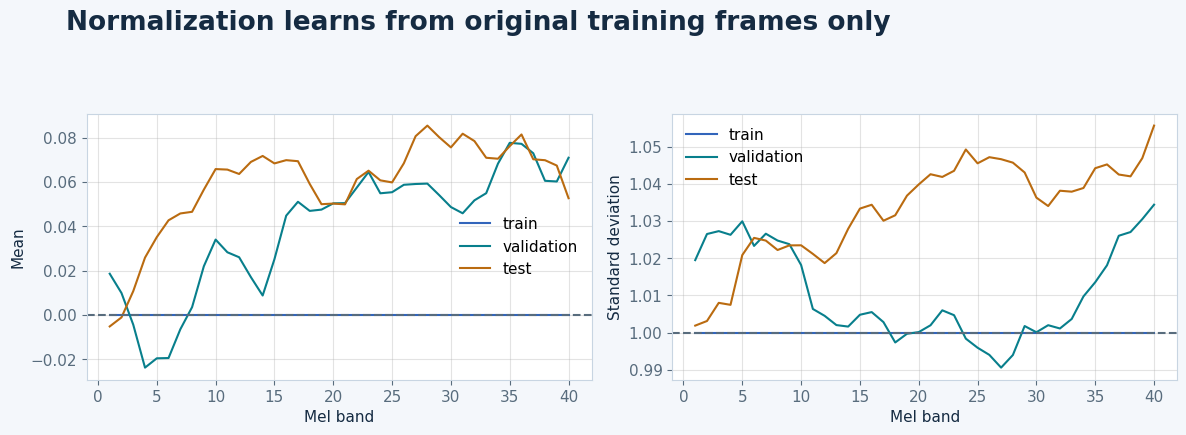

In [7]:
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for split,color in zip(("train","validation","test"),(BLUE,TEAL,AMBER)):
    selected=[r for r in normalized if r["split"]==split and not r["is_augmented"]]
    count=0; summed=np.zeros(cfg["mel_bands"]); squared=summed.copy()
    for record in selected:
        values=np.load(root/record["normalized_path"]).astype(np.float64); count+=len(values); summed+=values.sum(0); squared+=(values*values).sum(0)
    band_mean=summed/count; band_std=np.sqrt(np.maximum(squared/count-band_mean**2,0))
    axes[0].plot(range(1,cfg["mel_bands"]+1),band_mean,label=split,color=color); axes[1].plot(range(1,cfg["mel_bands"]+1),band_std,label=split,color=color)
for ax,target,label in zip(axes,(0,1),("Mean","Standard deviation")):
    ax.axhline(target,color=MUTED,ls="--"); ax.set(xlabel="Mel band",ylabel=label); ax.legend(frameon=False); ax.grid(alpha=.35)
fig.suptitle("Normalization learns from original training frames only",x=.06,ha="left",fontsize=19,weight="bold",color=INK)
fig.tight_layout(rect=(0,.02,1,.88)); finish_figure(fig,"08_normalization")

Continue with [09 · Quality assurance](09_quality_assurance.ipynb).